# Preprocesamiento de las noches para XGBoost

El objetivo de este notebook es preparar los datos para un modelo XGBoost que clasifica cada época de 30 s en uno de los cinco estadios del sueño: **W, N1, N2, N3 y REM**. El modelo debe funcionar con cualquier combinación de canales que incluya al menos un EEG (Fpz-Cz, Pz-Oz o ambos, con o sin EOG y con o sin EMG): son **12 combinaciones**.

Se usan las 153 noches de Sleep Cassette (Sleep-EDF Expanded). Cada época se describe con **719 rasgos** calculados a partir de la señal, y la tabla se guarda en `data/procesados/xgboost/rasgos.parquet` para entrenar el modelo en `2_entrenamiento.ipynb`.

El notebook se organiza así:

1. **Librerías**
2. **Rutas y parámetros**
3. **Lectura de las noches:** archivos, etiquetas por época, ventana de sueño y una noche de ejemplo.
4. **Rasgos base:** espectro y forma de la señal del EEG, EOG, EMG y hora de la noche.
5. **Ondículas y pendiente 1/f**
6. **Contexto entre épocas**
7. **Tabla final**

## 1. Librerías

In [1]:
import warnings
from pathlib import Path

import antropy as ant
import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import pywt
from joblib import Parallel, delayed
from scipy import signal, stats

warnings.filterwarnings("ignore")
mne.set_log_level("ERROR")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Rutas y parámetros

Los datos van en `data/`, en la raíz del repositorio:

- `data/sleep-cassette/`: los 306 archivos EDF (señales + hipnograma de las 153 noches).
- `data/SC-subjects.xls`: datos de cada noche; aquí se usa la hora en que se apagó la luz.

Lo que se calcula queda en `data/procesados/xgboost/`. Si ya existe, se lee y no se vuelve a calcular.

In [2]:
# Raíz del repositorio: la carpeta que tiene particiones.json
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "particiones.json").exists())
DATA = RAIZ / "data"
EDF = DATA / "sleep-cassette"
SUJETOS_XLS = DATA / "SC-subjects.xls"
PROCESADOS = DATA / "procesados" / "xgboost"
PROCESADOS.mkdir(parents=True, exist_ok=True)

N_PROCESOS = 8      # procesos para calcular los rasgos en paralelo
FS = 100            # Hz de EEG y EOG
EPOCH = 30          # segundos por época
ESTADIOS = ["W", "N1", "N2", "N3", "REM"]
CHANNELS = {"fpz": "EEG Fpz-Cz", "pz": "EEG Pz-Oz", "eog": "EOG horizontal", "emg": "EMG submental"}

## 3. Lectura de las noches

### Archivos

Cada noche `SC4ssN` (ss = sujeto, N = noche) tiene un archivo de señales (`*-PSG.edf`) y uno de anotaciones (`*-Hypnogram.edf`). Listamos las parejas de archivos.

In [3]:
# Función para listar las noches con sus dos archivos
def list_nights(raw_dir):
    """[(noche, ruta_psg, ruta_hipnograma)] ordenado por noche."""
    psgs = {p.name[:6]: p for p in Path(raw_dir).glob("SC4*-PSG.edf")}
    hyps = {p.name[:6]: p for p in Path(raw_dir).glob("SC4*-Hypnogram.edf")}
    return [(k, psgs[k], hyps[k]) for k in sorted(psgs) if k in hyps]


nights = list_nights(EDF)
print(f"{len(nights)} noches en {EDF.relative_to(RAIZ)}")
print("primera:", nights[0][0], "|", nights[0][1].name, "|", nights[0][2].name)

153 noches en data/sleep-cassette
primera: SC4001 | SC4001E0-PSG.edf | SC4001EC-Hypnogram.edf


### Etiquetas por época

Las anotaciones vienen en la norma R&K, con inicio y duración en segundos. Las pasamos a una etiqueta por época de 30 s y a la norma AASM: S3 y S4 se juntan en N3. Las épocas `Sleep stage ?` y `Movement time` no tienen estadio y quedan con etiqueta −1.

In [4]:
# Función para convertir el hipnograma en una etiqueta por época
STAGE_MAP = {"Sleep stage W": 0, "Sleep stage 1": 1, "Sleep stage 2": 2,
             "Sleep stage 3": 3, "Sleep stage 4": 3, "Sleep stage R": 4}
UNKNOWN = -1


def hypnogram_labels(hyp_path, n_epochs, epoch_sec=EPOCH):
    """Etiqueta (0..4 o -1) de cada época del registro, contando desde su inicio."""
    ann = mne.read_annotations(hyp_path)
    labels = np.full(n_epochs, UNKNOWN, dtype=np.int64)
    for onset, duration, desc in zip(ann.onset, ann.duration, ann.description):
        start = int(round(onset / epoch_sec))
        stop = min(start + int(round(duration / epoch_sec)), n_epochs)
        labels[start:stop] = STAGE_MAP.get(desc, UNKNOWN)
    return labels

### Ventana de sueño

Cada registro dura ~22 h y casi todo es vigilia. Conservamos solo la **ventana de sueño**: desde 30 min antes del primer estadio de sueño hasta 30 min después del último.

In [5]:
# Función para encontrar la ventana de sueño de una noche
def sleep_window(labels, wake_margin_min=30, epoch_sec=EPOCH):
    """(primera, última) época del periodo de sueño, con 30 min de vigilia a cada lado."""
    sleep_idx = np.where(labels > 0)[0]
    margin = int(wake_margin_min * 60 / epoch_sec)
    return max(sleep_idx[0] - margin, 0), min(sleep_idx[-1] + margin, len(labels) - 1)

### Ejemplo: una noche

Leemos la primera noche para ver cómo es un registro: cuánto dura, cuánto de eso es la ventana de sueño y cómo cambian los estadios.

In [6]:
# Lectura de la primera noche
nid, psg, hyp = nights[0]
raw = mne.io.read_raw_edf(psg, include=list(CHANNELS.values()), preload=True, verbose="error")
n_epochs = int(raw.n_times // (FS * EPOCH))
labels = hypnogram_labels(hyp, n_epochs)
first, last = sleep_window(labels)
print(f"{nid}: {raw.n_times / FS / 3600:.1f} h de registro, {n_epochs} épocas")
print(f"ventana de sueño: épocas {first} a {last} ({(last - first + 1) * EPOCH / 3600:.1f} h)")

SC4001: 22.1 h de registro, 2650 épocas
ventana de sueño: épocas 961 a 1801 (7.0 h)


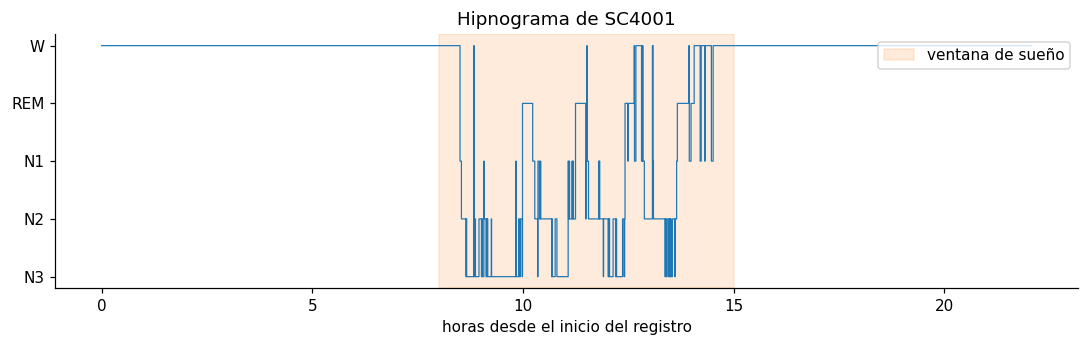

In [7]:
# Hipnograma de la noche, con la ventana de sueño sombreada
orden = [0, 4, 1, 2, 3]  # W, REM, N1, N2 y N3, de arriba a abajo
altura = {e: i for i, e in enumerate(orden)}
h = np.array([altura.get(v, np.nan) for v in labels], dtype=float)
horas = np.arange(n_epochs) * EPOCH / 3600

fig, ax = plt.subplots(figsize=(12, 3))
ax.step(horas, h, where="post", lw=0.8)
ax.axvspan(horas[first], horas[last], color="tab:orange", alpha=0.15, label="ventana de sueño")
ax.set_yticks(range(5), [ESTADIOS[e] for e in orden])
ax.invert_yaxis()
ax.set_xlabel("horas desde el inicio del registro")
ax.set_title(f"Hipnograma de {nid}")
ax.legend(loc="upper right")
plt.show()

Vemos cómo se ve la señal de Fpz-Cz en una época de cada estadio. En N3 dominan las ondas lentas y grandes; en W y REM la señal es más rápida y de menor amplitud.

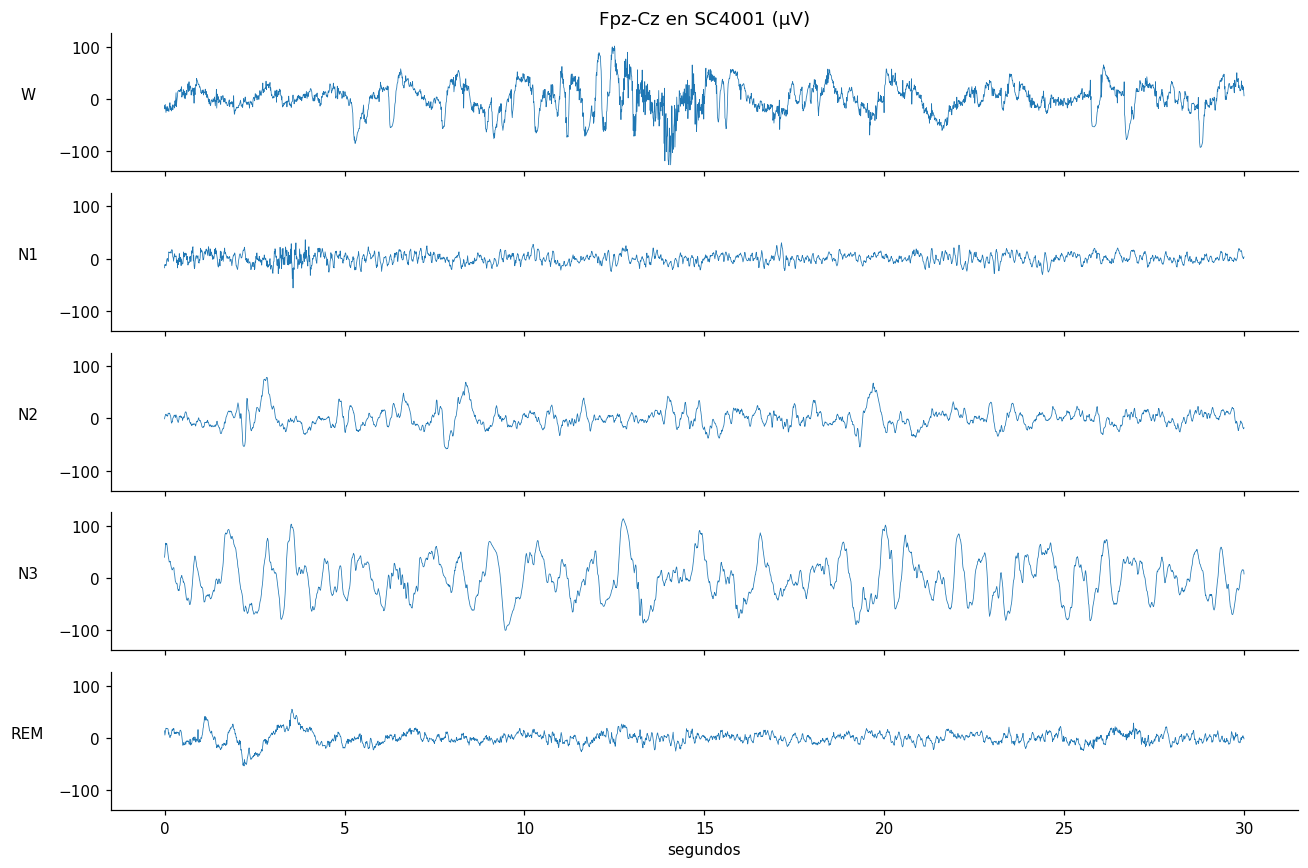

In [8]:
# Una época de 30 s de Fpz-Cz por estadio (la del medio de cada estadio en esta noche)
fpz = raw.get_data(picks=CHANNELS["fpz"])[0] * 1e6  # V -> µV
t = np.arange(FS * EPOCH) / FS

fig, axes = plt.subplots(5, 1, figsize=(12, 8), sharex=True, sharey=True)
for ax, e in zip(axes, range(5)):
    ep = np.where(labels == e)[0]
    i = ep[len(ep) // 2]
    ax.plot(t, fpz[i * FS * EPOCH:(i + 1) * FS * EPOCH], lw=0.5)
    ax.set_ylabel(ESTADIOS[e], rotation=0, labelpad=20)
axes[0].set_title(f"Fpz-Cz en {nid} (µV)")
axes[-1].set_xlabel("segundos")
plt.tight_layout()
plt.show()

## 4. Rasgos base

Los rasgos se calculan sobre la ventana de sueño completa, **incluidas las épocas sin etiqueta**, para no romper la continuidad cuando después se miren las épocas vecinas.

El prefijo de cada columna dice de qué canal sale (`fpz_`, `pz_`, `eog_`, `emg_`, `time_`). Eso es lo que permite después apagar un canal completo.

### EEG: espectro

Con el método de Welch (ventanas de 4 s) calculamos la potencia absoluta y relativa en delta lenta (0.5–1 Hz), delta (1–4), theta (4–8), alfa (8–12), sigma (12–16) y beta (16–30), además de la potencia total, cocientes entre bandas, SEF95, frecuencia pico y entropía espectral.

In [9]:
# Función para los rasgos espectrales de un canal de EEG
EEG_BANDS = {"sdelta": (0.5, 1), "delta": (1, 4), "theta": (4, 8), "alpha": (8, 12), "sigma": (12, 16), "beta": (16, 30)}
EPS = 1e-12


def _band_power(f, psd, lo, hi):
    idx = (f >= lo) & (f < hi)
    return psd[:, idx].sum(1) * (f[1] - f[0])


def eeg_spectral(x, p):
    """x: (n_épocas, 3000) en µV. p: prefijo del canal."""
    out = {}
    f, psd = signal.welch(x, fs=FS, nperseg=4 * FS, noverlap=2 * FS, axis=-1)
    total = _band_power(f, psd, 0.5, 30) + EPS
    bp = {b: _band_power(f, psd, lo, hi) + EPS for b, (lo, hi) in EEG_BANDS.items()}
    for b, v in bp.items():
        out[f"{p}_abs_{b}"] = np.log10(v)
        out[f"{p}_rel_{b}"] = v / total
    out[f"{p}_abs_total"] = np.log10(total)
    out[f"{p}_ratio_delta_theta"] = np.log10(bp["delta"] / bp["theta"])
    out[f"{p}_ratio_delta_beta"] = np.log10(bp["delta"] / bp["beta"])
    out[f"{p}_ratio_theta_alpha"] = np.log10(bp["theta"] / bp["alpha"])
    out[f"{p}_ratio_slow_fast"] = np.log10((bp["delta"] + bp["theta"]) / (bp["alpha"] + bp["beta"]))

    band = (f >= 0.5) & (f < 30)
    fb, pb = f[band], psd[:, band] + EPS
    cum = np.cumsum(pb, 1) / pb.sum(1, keepdims=True)
    out[f"{p}_sef95"] = fb[np.argmax(cum >= 0.95, axis=1)]
    out[f"{p}_peak_freq"] = fb[np.argmax(pb, 1)]
    pn = pb / pb.sum(1, keepdims=True)
    out[f"{p}_spec_entropy"] = -(pn * np.log2(pn)).sum(1) / np.log2(pn.shape[1])
    return out

### EEG: forma de la señal

Medidas en el tiempo: desviación, IQR, asimetría, curtosis, parámetros de Hjorth, cruces por cero, longitud de línea, entropía de permutación y dimensión fractal de Higuchi.

In [10]:
# Función para los rasgos de forma de un canal de EEG
def eeg_shape(x, p):
    out = {}
    out[f"{p}_std"] = x.std(1)
    q75, q25 = np.percentile(x, [75, 25], axis=1)
    out[f"{p}_iqr"] = q75 - q25
    out[f"{p}_skew"] = stats.skew(x, axis=1)
    out[f"{p}_kurt"] = stats.kurtosis(x, axis=1)
    mob, comp = ant.hjorth_params(x, axis=1)
    out[f"{p}_hjorth_mob"], out[f"{p}_hjorth_comp"] = mob, comp
    out[f"{p}_zcr"] = ant.num_zerocross(x, normalize=True, axis=1)
    out[f"{p}_line_length"] = np.abs(np.diff(x, axis=1)).mean(1)
    out[f"{p}_perm_entropy"] = np.array([ant.perm_entropy(v, order=3, normalize=True) for v in x])
    out[f"{p}_higuchi"] = np.array([ant.higuchi_fd(v.astype(np.float64)) for v in x])
    return out

### EEG: sub-ventanas de 5 s

Los husos y los complejos K duran menos de 2 s, así que se notan mejor en ventanas cortas. Partimos cada época en 6 sub-ventanas de 5 s y guardamos el máximo y la variación de la potencia sigma y delta, y de la amplitud pico a pico.

In [11]:
# Función para los rasgos de las sub-ventanas de 5 s
def eeg_subwindows(x, p):
    out = {}
    sub = x.reshape(len(x), 6, 5 * FS)
    fs_, psub = signal.welch(sub, fs=FS, nperseg=250, noverlap=125, axis=-1)
    for b, (lo, hi) in [("sigma", (12, 16)), ("delta", (0.5, 4))]:
        idx = (fs_ >= lo) & (fs_ < hi)
        lp = np.log10(psub[..., idx].sum(-1) * (fs_[1] - fs_[0]) + EPS)
        out[f"{p}_sub_{b}_max"] = lp.max(1)
        out[f"{p}_sub_{b}_std"] = lp.std(1)
    ptp = np.ptp(sub, axis=-1)
    out[f"{p}_sub_ptp_max"] = ptp.max(1)
    out[f"{p}_sub_ptp_std"] = ptp.std(1)
    return out

Juntamos las tres partes: son **36 rasgos por canal de EEG**.

In [12]:
# Función con todos los rasgos de un canal de EEG
def eeg_features(x, p):
    return {**eeg_spectral(x, p), **eeg_shape(x, p), **eeg_subwindows(x, p)}


ej = eeg_features(fpz[first * FS * EPOCH:(first + 3) * FS * EPOCH].reshape(3, FS * EPOCH), "fpz")
print(len(ej), "rasgos de EEG |", list(ej)[:6], "...")

36 rasgos de EEG | ['fpz_abs_sdelta', 'fpz_rel_sdelta', 'fpz_abs_delta', 'fpz_rel_delta', 'fpz_abs_theta', 'fpz_rel_theta'] ...


### EOG

Potencia de los movimientos oculares lentos (0.3–2 Hz) y rápidos (2–5 Hz), amplitud y la correlación con Fpz-Cz, que es frontal y capta parte del movimiento ocular. Esta última **depende de Fpz-Cz** aunque su prefijo sea `eog_`, y se apaga también cuando falta Fpz-Cz.

In [13]:
# Función para los rasgos del EOG
def eog_features(x, fpz=None):
    out = {}
    f, psd = signal.welch(x, fs=FS, nperseg=4 * FS, noverlap=2 * FS, axis=-1)
    out["eog_abs_slow"] = np.log10(_band_power(f, psd, 0.3, 2) + EPS)
    out["eog_abs_rapid"] = np.log10(_band_power(f, psd, 2, 5) + EPS)
    out["eog_abs_total"] = np.log10(_band_power(f, psd, 0.3, 30) + EPS)
    out["eog_std"] = x.std(1)
    out["eog_line_length"] = np.abs(np.diff(x, axis=1)).mean(1)
    out["eog_max_abs"] = np.abs(x).max(1)
    out["eog_kurt"] = stats.kurtosis(x, axis=1)
    if fpz is not None:
        xc = x - x.mean(1, keepdims=True)
        fc = fpz - fpz.mean(1, keepdims=True)
        out["eog_corr_fpz"] = (xc * fc).sum(1) / (np.sqrt((xc**2).sum(1) * (fc**2).sum(1)) + EPS)
    return out

### EMG

El EMG viene a 1 Hz (es una envolvente: 30 valores por época), así que solo resumimos esos 30 valores.

In [14]:
# Función para los rasgos del EMG
def emg_features(v):
    """v: (n_épocas, 30) valores a 1 Hz de la envolvente del EMG, en µV."""
    return {"emg_mean": v.mean(1), "emg_median": np.median(v, 1), "emg_std": v.std(1),
            "emg_min": v.min(1), "emg_max": v.max(1), "emg_log_mean": np.log10(np.abs(v.mean(1)) + EPS)}

### Hora de la noche

Horas desde que se apagó la luz. N3 se concentra al inicio de la noche y REM al final.

In [15]:
# Función para calcular cuándo se apagó la luz, contando desde el inicio del registro
def lights_off_offset(meas_date, lights_off):
    """Segundos desde el inicio del registro hasta que se apagó la luz."""
    start = meas_date.hour * 3600 + meas_date.minute * 60 + meas_date.second
    lo = lights_off.hour * 3600 + lights_off.minute * 60 + lights_off.second
    delta = lo - start
    return delta + 86400 if delta < 0 else delta

### Rasgos de una noche

Juntamos todo en una función que lee una noche, corta la ventana de sueño en épocas y calcula los rasgos base de los 4 canales.

In [16]:
# Función para calcular los rasgos base de una noche
def extract_night(job):
    """job = (noche, psg, hipnograma, hora de apagado de la luz)."""
    nid, psg, hyp, lights_off = job
    warnings.filterwarnings("ignore")
    raw = mne.io.read_raw_edf(psg, include=list(CHANNELS.values()), preload=True, verbose="error")
    n_epochs = int(raw.n_times // (FS * EPOCH))
    labels = hypnogram_labels(hyp, n_epochs, EPOCH)
    first, last = sleep_window(labels)
    idx = np.arange(first, last + 1)

    data = {k: raw.get_data(picks=ch)[0] * 1e6 for k, ch in CHANNELS.items()}  # V -> µV
    cut = lambda s: s[: n_epochs * FS * EPOCH].reshape(n_epochs, FS * EPOCH)[idx]  # noqa: E731
    fpz, pz, eog = cut(data["fpz"]), cut(data["pz"]), cut(data["eog"])
    # MNE interpola el EMG (1 Hz) a 100 Hz: cada 100 muestras está el valor original
    emg = data["emg"][: n_epochs * FS * EPOCH : FS].reshape(n_epochs, EPOCH)[idx]

    feats = {**eeg_features(fpz, "fpz"), **eeg_features(pz, "pz"), **eog_features(eog, fpz), **emg_features(emg)}
    offset = lights_off_offset(raw.info["meas_date"], lights_off)
    df = pd.DataFrame(feats).astype(np.float32)
    df.insert(0, "time_hours_since_lights_off", ((idx * EPOCH - offset) / 3600).astype(np.float32))
    df.insert(0, "y", labels[idx])
    df.insert(0, "epoch_idx", idx)
    df.insert(0, "subject", int(nid[3:5]))
    df.insert(0, "night", nid)
    return df

Probamos la función con la primera noche.

In [17]:
# Rasgos base de la primera noche
meta = pd.read_excel(SUJETOS_XLS)
lights = {(int(r.subject), int(r.night)): r.LightsOff for _, r in meta.iterrows()}
jobs = [(n, p, h, lights[(int(n[3:5]), int(n[5]))]) for n, p, h in nights]

ejemplo = extract_night(jobs[0])
print(f"{ejemplo.night[0]}: {ejemplo.shape[0]} épocas × {ejemplo.shape[1]} columnas")
ejemplo.head()

SC4001: 841 épocas × 91 columnas


,night,subject,epoch_idx,y,time_hours_since_lights_off,fpz_abs_sdelta,fpz_rel_sdelta,fpz_abs_delta,fpz_rel_delta,fpz_abs_theta,...,eog_line_length,eog_max_abs,eog_kurt,eog_corr_fpz,emg_mean,emg_median,emg_std,emg_min,emg_max,emg_log_mean
0,SC4001,0,961,0,-0.408333,1.783696,0.144295,2.489612,0.733108,1.546322,...,19.643486,198.350433,2.057726,-0.115206,3.422800,3.426,0.060327,3.288,3.530,0.534382
1,SC4001,0,962,0,-0.400000,2.216792,0.270658,2.581941,0.627435,1.669802,...,22.793011,339.782898,5.483197,-0.074282,3.471267,3.478,0.059785,3.340,3.596,0.540488
2,SC4001,0,963,0,-0.391667,2.319117,0.235374,2.775406,0.673050,1.826854,...,23.352028,334.854950,0.583039,0.040808,3.406200,3.408,0.066592,3.276,3.514,0.532270
3,SC4001,0,964,0,-0.383333,2.121737,0.199830,2.658031,0.686995,1.714177,...,23.446018,386.105743,1.122365,-0.055320,3.418800,3.419,0.047240,3.336,3.530,0.533874
4,SC4001,0,965,0,-0.375000,2.294986,0.337769,2.515266,0.560918,1.636582,...,22.335709,320.563873,1.420724,-0.128225,3.454933,3.460,0.064380,3.328,3.560,0.538440


### Las 153 noches

Calculamos los rasgos de todas las noches en paralelo. El resultado se guarda y, si ya existe, se lee directamente.

In [18]:
# Rasgos base de las 153 noches
RASGOS_BASE = PROCESADOS / "rasgos_base.parquet"
if not RASGOS_BASE.exists():
    tablas = Parallel(n_jobs=N_PROCESOS)(delayed(extract_night)(j) for j in jobs)
    pd.concat(tablas, ignore_index=True).to_parquet(RASGOS_BASE)
    print("rasgos base calculados")

base = pd.read_parquet(RASGOS_BASE)
lab = base[base.y >= 0]
print(f"{base.night.nunique()} noches · {len(base):,} épocas en la ventana · {len(lab):,} con etiqueta")
assert len(lab) == 195_469

rasgos base calculados
153 noches · 195,767 épocas en la ventana · 195,469 con etiqueta


Revisamos cuántas épocas hay de cada estadio. Las clases están desbalanceadas: N2 domina, y N1 y N3 son las menos frecuentes.

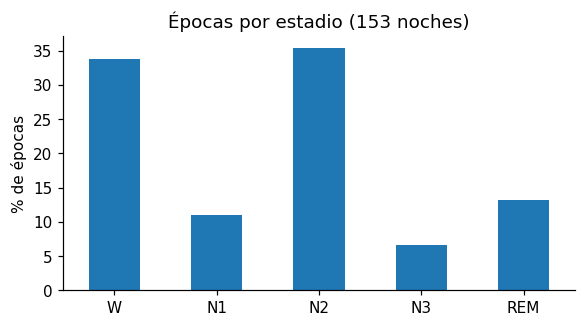

,W,N1,N2,N3,REM
épocas,65941,21522,69132,13039,25835


In [19]:
# Distribución de los estadios en las épocas con etiqueta
conteo = lab.y.value_counts().sort_index().set_axis(ESTADIOS)
ax = (conteo / conteo.sum() * 100).plot.bar(figsize=(6, 3), rot=0)
ax.set_ylabel("% de épocas")
ax.set_title("Épocas por estadio (153 noches)")
plt.show()
conteo.to_frame("épocas").T

## 5. Ondículas y pendiente 1/f

### Ondículas

Descomponemos cada época de Fpz-Cz, Pz-Oz y EOG con una ondícula biortogonal 2.2 en 4 niveles. Salen 5 sub-bandas: cA4 ≈ 0–3 Hz, cD4 ≈ 3–6, cD3 ≈ 6–12, cD2 ≈ 12–25 y cD1 ≈ 25–50 Hz. De cada una calculamos 8 medidas: log-energía, energía de Teager, movilidad y complejidad de Hjorth, curtosis, asimetría y dimensiones fractales de Katz y Petrosian.

In [20]:
# Función para los rasgos de ondículas de un canal
DWT_BANDS = ["cA4", "cD4", "cD3", "cD2", "cD1"]


def dwt_features(x, p):
    out = {}
    coeffs = pywt.wavedec(x, "bior2.2", level=4, axis=-1)
    for band, c in zip(DWT_BANDS, coeffs):
        q = f"{p}_dwt_{band}"
        out[f"{q}_logenergy"] = np.log10((c**2).mean(1) + EPS)
        out[f"{q}_teager"] = np.log10(np.abs(c[:, 1:-1] ** 2 - c[:, :-2] * c[:, 2:]).mean(1) + EPS)
        mob, comp = ant.hjorth_params(c, axis=1)
        out[f"{q}_hjorth_mob"], out[f"{q}_hjorth_comp"] = mob, comp
        out[f"{q}_kurt"] = stats.kurtosis(c, axis=1)
        out[f"{q}_skew"] = stats.skew(c, axis=1)
        out[f"{q}_katz"] = np.array([ant.katz_fd(v) for v in c])
        out[f"{q}_petrosian"] = np.array([ant.petrosian_fd(v) for v in c])
    return out

### Pendiente 1/f

El espectro del EEG tiene una parte "de fondo" que cae como 1/f, y su pendiente cambia con el nivel de alerta (W, N1, REM). Ajustamos una recta en escala log-log entre 2 y 30 Hz, sin la zona de 7.5–16 Hz, para que el alfa y los husos no la desvíen. Guardamos la pendiente, el intercepto y el R².

In [21]:
# Función para la pendiente 1/f de un canal de EEG
def aperiodic_features(x, p):
    f, psd = signal.welch(x, fs=FS, nperseg=4 * FS, noverlap=2 * FS, axis=-1)
    m = (f >= 2) & (f <= 30) & ~((f > 7.5) & (f < 16))
    lx = np.log10(f[m])
    ly = np.log10(psd[:, m] + EPS)
    A = np.vstack([lx, np.ones_like(lx)]).T
    coef, *_ = np.linalg.lstsq(A, ly.T, rcond=None)  # una recta por época
    pred = (A @ coef).T
    ss_res = ((ly - pred) ** 2).sum(1)
    ss_tot = ((ly - ly.mean(1, keepdims=True)) ** 2).sum(1) + EPS
    return {f"{p}_ap_slope": coef[0], f"{p}_ap_offset": coef[1], f"{p}_ap_r2": 1 - ss_res / ss_tot}

### Las 153 noches

Igual que con los rasgos base: una función por noche, en paralelo, y se guarda el resultado.

In [22]:
# Función para las ondículas y la pendiente 1/f de una noche
def extract_night_dwt(job):
    nid, psg, hyp = job
    warnings.filterwarnings("ignore")
    chans = {k: CHANNELS[k] for k in ("fpz", "pz", "eog")}
    raw = mne.io.read_raw_edf(psg, include=list(chans.values()), preload=True, verbose="error")
    n = int(raw.n_times // (FS * EPOCH))
    labels = hypnogram_labels(hyp, n, EPOCH)
    first, last = sleep_window(labels)
    idx = np.arange(first, last + 1)
    ep = {k: (raw.get_data(picks=ch)[0][: n * FS * EPOCH] * 1e6).reshape(n, FS * EPOCH)[idx] for k, ch in chans.items()}
    feats = {}
    for k in ("fpz", "pz", "eog"):
        feats.update(dwt_features(ep[k], k))
    for k in ("fpz", "pz"):
        feats.update(aperiodic_features(ep[k], k))
    df = pd.DataFrame(feats).astype(np.float32)
    df.insert(0, "epoch_idx", idx)
    df.insert(0, "night", nid)
    return df

In [23]:
# Ondículas y pendiente 1/f de las 153 noches
RASGOS_DWT = PROCESADOS / "rasgos_ondiculas_1f.parquet"
if not RASGOS_DWT.exists():
    tablas = Parallel(n_jobs=N_PROCESOS)(delayed(extract_night_dwt)(j) for j in nights)
    pd.concat(tablas, ignore_index=True).to_parquet(RASGOS_DWT)
    print("ondículas y 1/f calculadas")

dwt = pd.read_parquet(RASGOS_DWT)
print(dwt.shape, "| valores faltantes:", int(dwt.isna().sum().sum()))

ondículas y 1/f calculadas
(195767, 128) | valores faltantes: 0


## 6. Contexto entre épocas

Un técnico no califica una época sola: mira también las vecinas. Agregamos ese contexto, calculado dentro de cada noche y en orden:

1. **z-score robusto por noche** (mediana e IQR) de cada rasgo: compara la época con lo normal de esa persona esa noche (`*_z`).
2. **Medias móviles centradas** de 5 y 15 épocas (2.5 y 7.5 min) de los rasgos clave (`*_roll5`, `*_roll15`).
3. **Valores de las épocas t−2, t−1, t+1 y t+2** de esos mismos rasgos (`*_lagm2` … `*_lagp2`).

Se usa contexto futuro porque la calificación se hace sobre la noche completa, después de grabarla.

In [24]:
# Función para agregar el contexto entre épocas
META_COLS = ["night", "subject", "epoch_idx", "y"]
KEY_SUFFIXES = [
    "abs_sdelta", "abs_delta", "abs_theta", "abs_alpha", "abs_sigma", "abs_beta",
    "rel_delta", "rel_sigma", "ratio_slow_fast", "spec_entropy", "perm_entropy", "sub_sigma_max",
    "abs_slow", "abs_rapid", "std",          # EOG (y std del EEG)
    "mean", "log_mean",                      # EMG
    "ap_slope", "dwt_cD2_logenergy", "dwt_cD3_logenergy", "dwt_cA4_logenergy",
]


def base_feature_cols(df):
    return [c for c in df.columns if c not in META_COLS and not c.startswith("time_")]


def add_context(df, rolls=(5, 15), lags=(-2, -1, 1, 2)):
    df = df.sort_values(["night", "epoch_idx"]).reset_index(drop=True)
    base = base_feature_cols(df)
    g = df.groupby("night", sort=False)[base]
    med = g.transform("median")
    iqr = g.transform(lambda s: s.quantile(0.75) - s.quantile(0.25)).replace(0, 1.0)
    z = ((df[base] - med) / iqr).astype(np.float32)
    z.columns = [f"{c}_z" for c in base]

    keys = [f"{c}_z" for c in base if any(c.endswith("_" + s) for s in KEY_SUFFIXES)]
    gz = z[keys].groupby(df["night"], sort=False)
    parts = [df, z]
    for w in rolls:
        r = gz.rolling(w, center=True, min_periods=1).mean().reset_index(level=0, drop=True).sort_index()
        r.columns = [f"{c}_roll{w}" for c in keys]
        parts.append(r.astype(np.float32))
    for k in lags:
        s = gz.shift(-k)  # lag +1 = la época siguiente
        s.columns = [f"{c}_lag{'p' if k > 0 else 'm'}{abs(k)}" for c in keys]
        parts.append(s.astype(np.float32))
    return pd.concat(parts, axis=1)

Unimos los rasgos base con las ondículas y agregamos el contexto.

In [25]:
# Tabla completa con contexto
feat = base.merge(dwt, on=["night", "epoch_idx"], how="left", validate="one_to_one")
assert not feat.isna().any().any()
full = add_context(feat)

CHANNELS_ALL = ("fpz", "pz", "eog", "emg")
prefixes = tuple(f"{c}_" for c in CHANNELS_ALL) + ("time_",)
cols = [c for c in full.columns if c not in META_COLS and c.startswith(prefixes)]
print(f"tabla: {full.shape[0]:,} épocas × {len(cols)} columnas del modelo")

tabla: 195,767 épocas × 719 columnas del modelo


## 7. Tabla final

Revisamos cuántas columnas salen de cada canal y guardamos la tabla. El orden de las columnas importa: XGBoost sortea columnas por posición (`colsample_bytree`), así que con otro orden el modelo sale distinto. Por eso la tabla se guarda en este orden.

In [26]:
# Columnas por canal
pd.Series({c: sum(x.startswith(c + "_") for x in cols) for c in ("fpz", "pz", "eog", "emg", "time")}).to_frame("columnas").T

,fpz,pz,eog,emg,time
columnas,278,278,132,30,1


In [27]:
# Guardar la tabla de rasgos
RASGOS = PROCESADOS / "rasgos.parquet"
full[META_COLS + cols].to_parquet(RASGOS)
print("guardado:", RASGOS.relative_to(RAIZ))

guardado: data/procesados/xgboost/rasgos.parquet
